# Streaming decision tree demo — `numcompute_stream`

This notebook shows the whole framework working on a real data stream:

1. **Load** a CSV file with our own I/O module (`io.py`).
2. **Split** it into chunks to simulate data arriving over time.
3. **Train** a pipeline (`Imputer → StandardScaler → DecisionTreeClassifier`) chunk by chunk with `.partial_fit()`, using test-then-train evaluation.
4. **Log and plot** accuracy and other metrics over time with `visualise.py`, compare two buffer sizes, and check predictions on the latest chunk.

**Data:** the Electricity Market data set (45,312 half-hourly records from New South Wales, Australia, 1996–1998). The label says whether the price went **up (1)** or **down (0)**. The way prices behave changes over time (concept drift), so it is a realistic stream. See `data/README.md`.

In [1]:
import sys
from pathlib import Path

import numpy as np

# Make the package importable whether the notebook is started from the
# project folder or from demo/.
ROOT = Path.cwd().resolve()
if ROOT.name == "demo":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from numcompute_stream import (
    ROCAUC, F1, Accuracy, DecisionTreeClassifier, Imputer, Pipeline,
    StandardScaler, StreamTrainer, StreamingHistogram, StreamingStats,
    chunk_array, iter_csv_chunks, read_csv,
)
from numcompute_stream.visualise import (
    compare_models, plot_metric_over_time, plot_predictions_vs_ground_truth,
)

DATA = ROOT / "data" / "elec.csv"
FIGURES = ROOT / "demo" / "figures"
FIGURES.mkdir(exist_ok=True)
print("NumPy", np.__version__)

NumPy 2.5.3


## 1. Load the CSV with our own reader

`read_csv` handles the header, takes the label column out by name and turns empty or `NA` cells into NaN. It returns `(X, y, feature_names)`.

In [2]:
X, y, feature_names = read_csv(DATA, label_column="class")

print("X shape:", X.shape)
print("features:", feature_names)
labels, counts = np.unique(y, return_counts=True)
for label, count in zip(labels, counts):
    print(f"class {label}: {count} rows ({count / len(y):.1%})")
print("missing values:", int(np.isnan(X).sum()))
print("first 3 rows:\n", X[:3].round(3))

X shape: (45312, 6)
features: ['period', 'nswprice', 'nswdemand', 'vicprice', 'vicdemand', 'transfer']
class 0: 26075 rows (57.5%)
class 1: 19237 rows (42.5%)
missing values: 0
first 3 rows:
 [[0.    0.056 0.439 0.003 0.423 0.415]
 [0.021 0.052 0.415 0.003 0.423 0.415]
 [0.043 0.051 0.385 0.003 0.423 0.415]]


## 2. Streaming statistics

Before training, `StreamingStats` summarises the stream one chunk at a time (running mean and variance with the Chan/Welford merge, quantiles from a fixed-size reservoir sample). The result matches NumPy on the full array, without ever holding more than one chunk.

In [3]:
stats = StreamingStats(random_state=0)
for X_chunk, _ in chunk_array(X, chunk_size=1000):
    stats.update_stats(X_chunk)

print(f"{'feature':>10} {'mean':>8} {'std':>8} {'median':>8}")
for name, m, s, q in zip(feature_names, stats.mean_, stats.std_, stats.median()):
    print(f"{name:>10} {m:8.4f} {s:8.4f} {q:8.4f}")

print("\nstreamed mean == NumPy mean:", np.allclose(stats.mean_, X.mean(axis=0)))
print("streamed std  == NumPy std: ", np.allclose(stats.std_, X.std(axis=0)))

   feature     mean      std   median
    period   0.5000   0.2948   0.5106
  nswprice   0.0579   0.0400   0.0484
 nswdemand   0.4254   0.1633   0.4426
  vicprice   0.0035   0.0102   0.0035
 vicdemand   0.4229   0.1210   0.4229
  transfer   0.5005   0.1534   0.4149

streamed mean == NumPy mean: True
streamed std  == NumPy std:  True


## 3. Simulate the stream and train incrementally

`iter_csv_chunks` reads the file **250 rows at a time** (about five days of data), so only one chunk is in memory, like a live feed.

The model is a pipeline. On each chunk, the `StreamTrainer` does **test-then-train**:

1. predict the new chunk with the current model and update the metrics (the model has not seen this chunk yet, so this is an honest score);
2. call `pipe.partial_fit(X_chunk, y_chunk)`.

The tree uses **buffered retraining** with `buffer_size=1000`: chunks are collected in a buffer, and every time it holds 1000 rows the tree is rebuilt on them and the buffer is cleared. Between retrains, predictions come from the last tree.

In [4]:
CHUNK_SIZE = 250

pipe = Pipeline([
    ("impute", Imputer(strategy="mean")),
    ("scale", StandardScaler()),
    ("model", DecisionTreeClassifier(max_depth=5, buffer_size=1000)),
])
trainer = StreamTrainer(pipe, metrics={
    "accuracy": Accuracy(),
    "rolling_accuracy": Accuracy(window=10),
    "f1_macro": F1(average="macro"),
    "auc": ROCAUC(pos_label=1),
})

chunks = list(iter_csv_chunks(DATA, CHUNK_SIZE, label_column="class"))
print("number of chunks:", len(chunks))

# Stream every chunk except the last; we keep the last one as "brand new"
# data for section 6.
for X_chunk, y_chunk, _ in chunks[:-1]:
    trainer.process_chunk(X_chunk, y_chunk)

print("\nLog of the first 8 chunks and the last 3:")
for record in trainer.history_[:8] + trainer.history_[-3:]:
    print(trainer.format_record(record))

number of chunks: 182



Log of the first 8 chunks and the last 3:
chunk   1 | seen    250 | chunk acc   -   | cumulative acc   -   | buffer 250 | mem 14.4 KB
chunk   2 | seen    500 | chunk acc   -   | cumulative acc   -   | buffer 500 | mem 28.1 KB
chunk   3 | seen    750 | chunk acc   -   | cumulative acc   -   | buffer 750 | mem 41.8 KB
chunk   4 | seen   1000 | chunk acc   -   | cumulative acc   -   | buffer 0 | mem 3.0 KB  RETRAINED
chunk   5 | seen   1250 | chunk acc 0.808 | cumulative acc 0.808 | buffer 250 | mem 16.6 KB
chunk   6 | seen   1500 | chunk acc 0.856 | cumulative acc 0.832 | buffer 500 | mem 30.3 KB
chunk   7 | seen   1750 | chunk acc 0.688 | cumulative acc 0.784 | buffer 750 | mem 44.0 KB
chunk   8 | seen   2000 | chunk acc 0.608 | cumulative acc 0.740 | buffer 0 | mem 4.1 KB  RETRAINED
chunk 179 | seen  44750 | chunk acc 0.792 | cumulative acc 0.745 | buffer 750 | mem 45.0 KB
chunk 180 | seen  45000 | chunk acc 0.892 | cumulative acc 0.746 | buffer 0 | mem 4.2 KB  RETRAINED
chunk 181 | s

The first three chunks are not scored (`-`) because the first tree only exists once 1000 rows have been buffered (chunk 4). After that the tree retrains every fourth chunk (`RETRAINED`), and memory stays small because the buffer is emptied each time.

In [5]:
summary = trainer.summary()
for key, value in summary.items():
    print(f"{key:>26}: {value:.4f}" if isinstance(value, float) else f"{key:>26}: {value}")

                    chunks: 181
              samples_seen: 45250
 final_cumulative_accuracy: 0.7461
                  retrains: 45
         total_fit_seconds: 0.2557
         peak_memory_bytes: 46904
                  accuracy: 0.7461
          rolling_accuracy: 0.7992
                  f1_macro: 0.7380
                       auc: 0.7922


## 4. Metrics over time

Dotted lines mark every fifth retrain of the tree (it retrains every 4 chunks, so drawing all 45 would hide the curve). Cumulative accuracy is the overall score so far; rolling accuracy (last 10 chunks) shows how the model is doing *now*, which is where drift becomes visible.

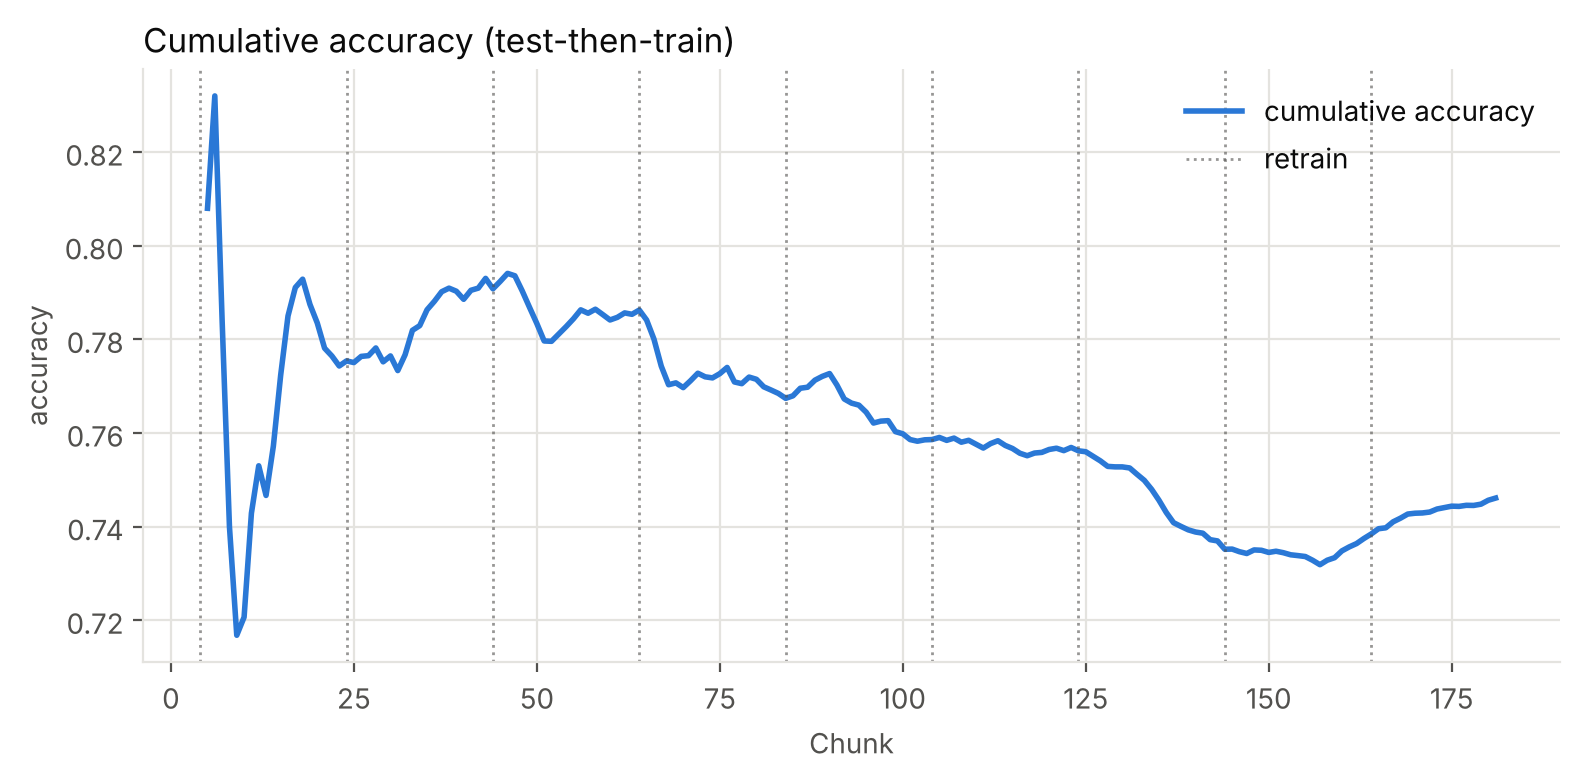

In [6]:
retrains = trainer.retrain_chunks()
plot_metric_over_time(trainer.get("cumulative_accuracy"),
                      title="Cumulative accuracy (test-then-train)",
                      ylabel="accuracy", label="cumulative accuracy",
                      retrain_points=retrains[::5],
                      save_path=FIGURES / "cumulative_accuracy.png");

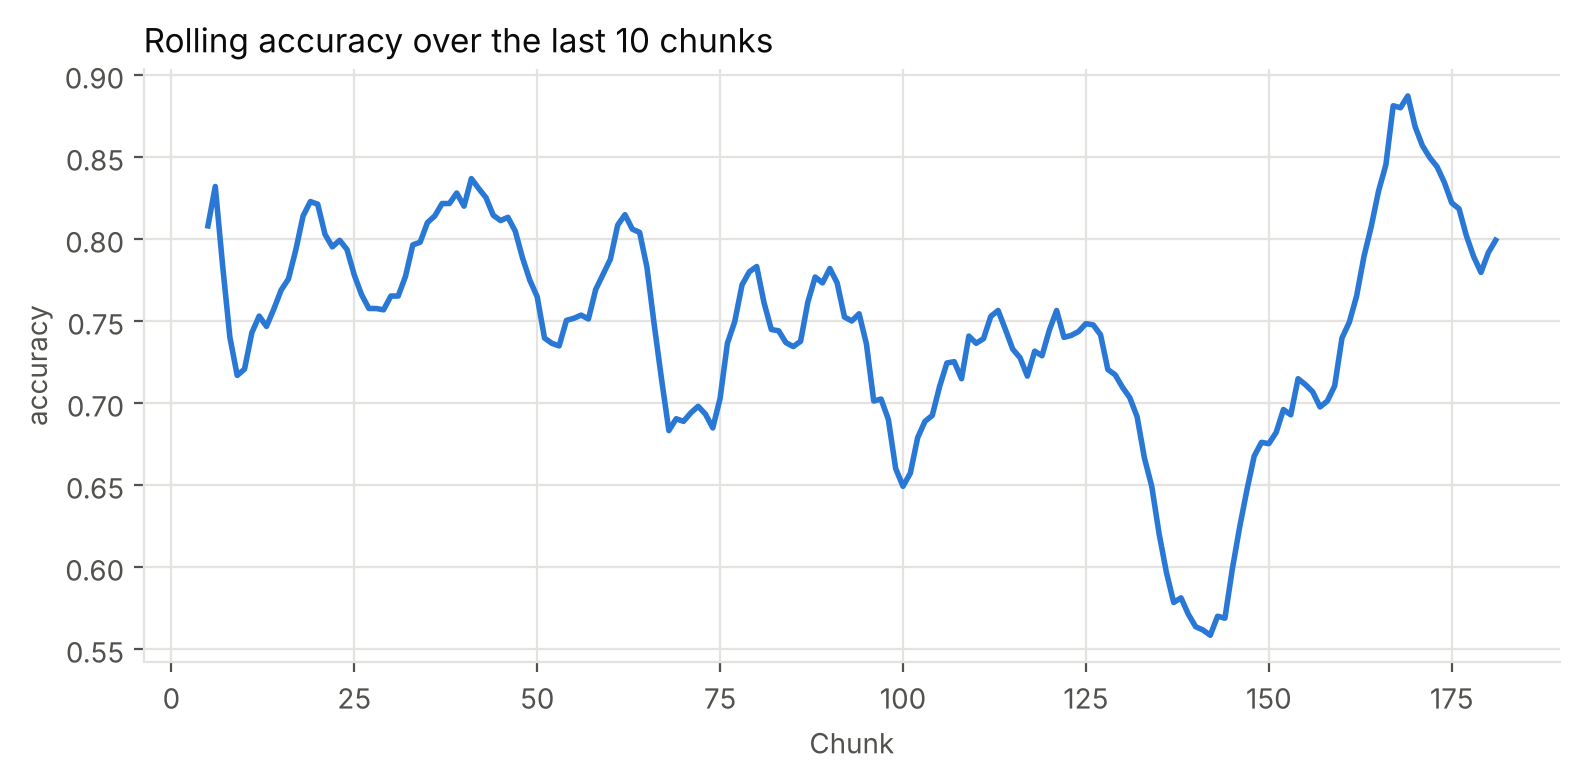

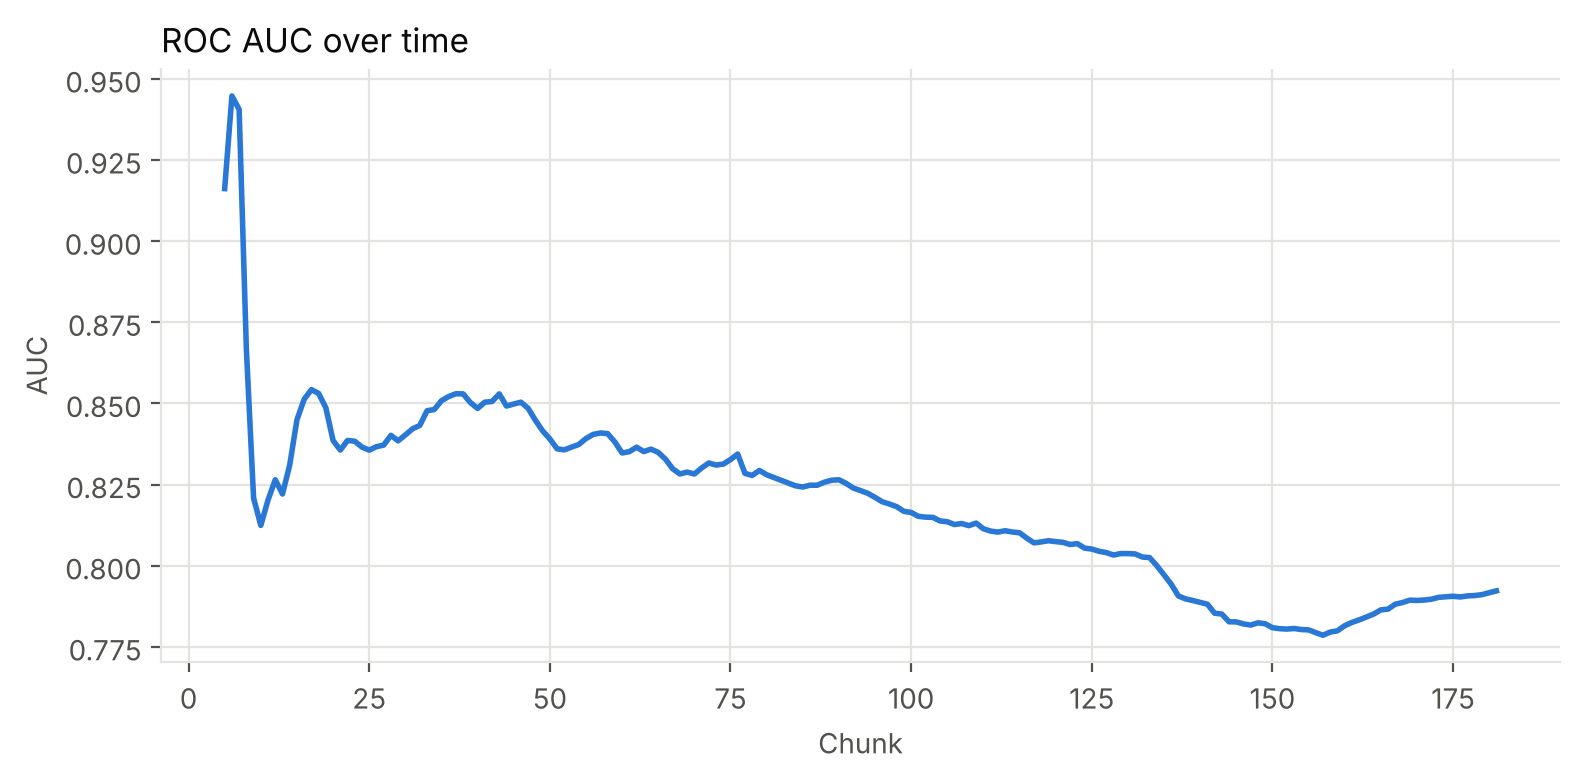

In [7]:
plot_metric_over_time(trainer.get("rolling_accuracy"),
                      title="Rolling accuracy over the last 10 chunks",
                      ylabel="accuracy",
                      save_path=FIGURES / "rolling_accuracy.png");
plot_metric_over_time(trainer.get("auc"), title="ROC AUC over time",
                      ylabel="AUC", save_path=FIGURES / "auc.png");

## 5. Compare two buffer sizes

The same pipeline is run with a small buffer (250 rows, retrains every chunk) and a large one (5000 rows, retrains every 20 chunks). A small buffer adapts quickly when the market changes; a large buffer trains on more data each time but its tree goes out of date between retrains.

buffer  250: final accuracy 0.7529, retrains 181, total fit time 0.507s
buffer 5000: final accuracy 0.7294, retrains 9, total fit time 0.300s


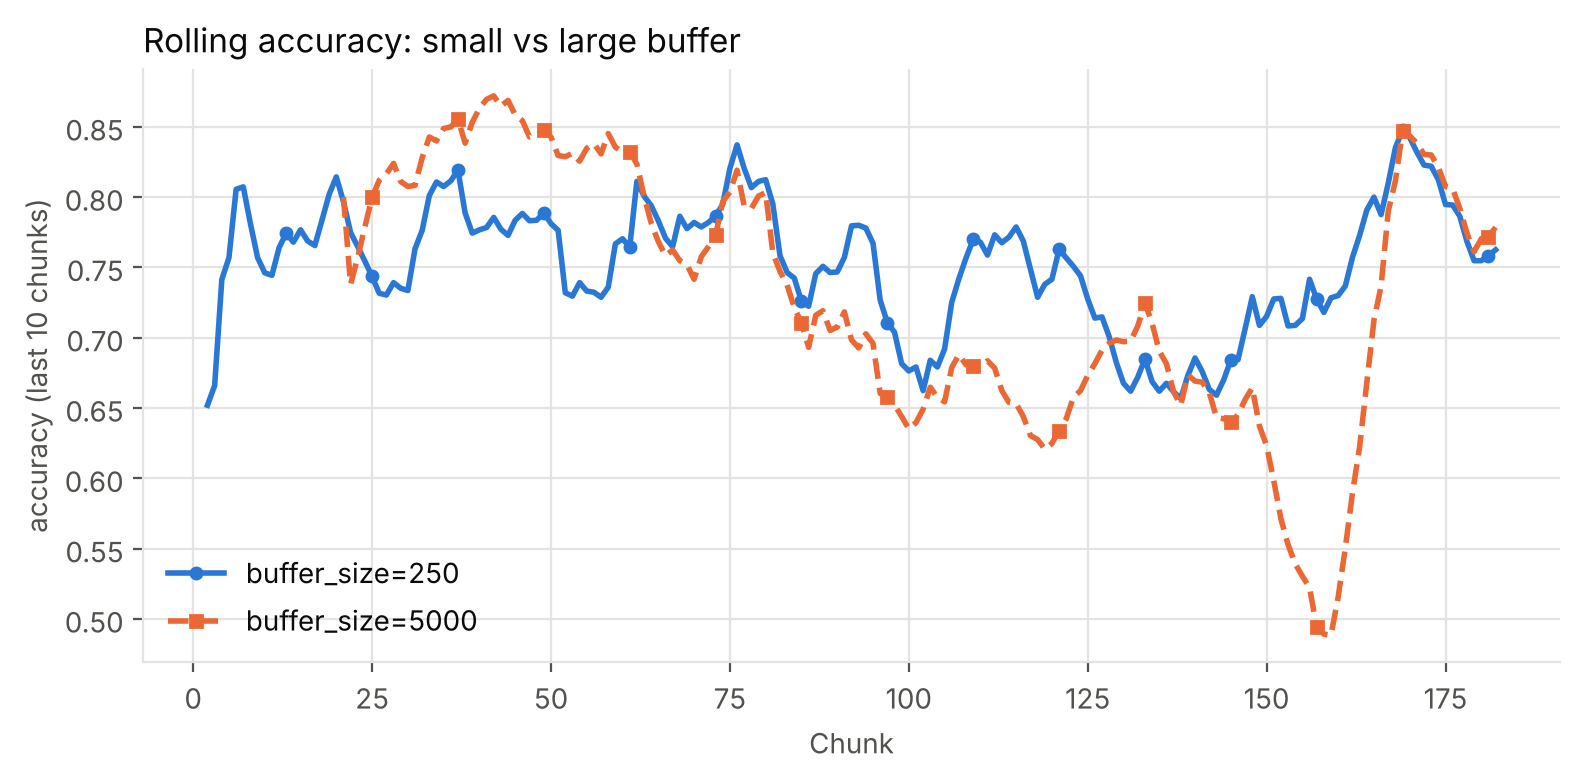

In [8]:
def run_stream(buffer_size):
    p = Pipeline([("impute", Imputer()), ("scale", StandardScaler()),
                  ("model", DecisionTreeClassifier(max_depth=5,
                                                   buffer_size=buffer_size))])
    t = StreamTrainer(p, rolling_window=10)
    t.run((c.X, c.y) for c in chunks)
    return t

small, large = run_stream(250), run_stream(5000)
compare_models(small.get("rolling_accuracy"), large.get("rolling_accuracy"),
               labels=["buffer_size=250", "buffer_size=5000"],
               title="Rolling accuracy: small vs large buffer",
               ylabel="accuracy (last 10 chunks)",
               save_path=FIGURES / "compare_buffers.png")

for name, t in (("250", small), ("5000", large)):
    s = t.summary()
    print(f"buffer {name:>4}: final accuracy {s['final_cumulative_accuracy']:.4f}, "
          f"retrains {s['retrains']}, total fit time {s['total_fit_seconds']:.3f}s")

## 6. Predictions vs ground truth on the latest chunk

The last chunk was held back, so the model has never seen it. Each circle is a true class and each cross the predicted class; red crosses are mistakes.

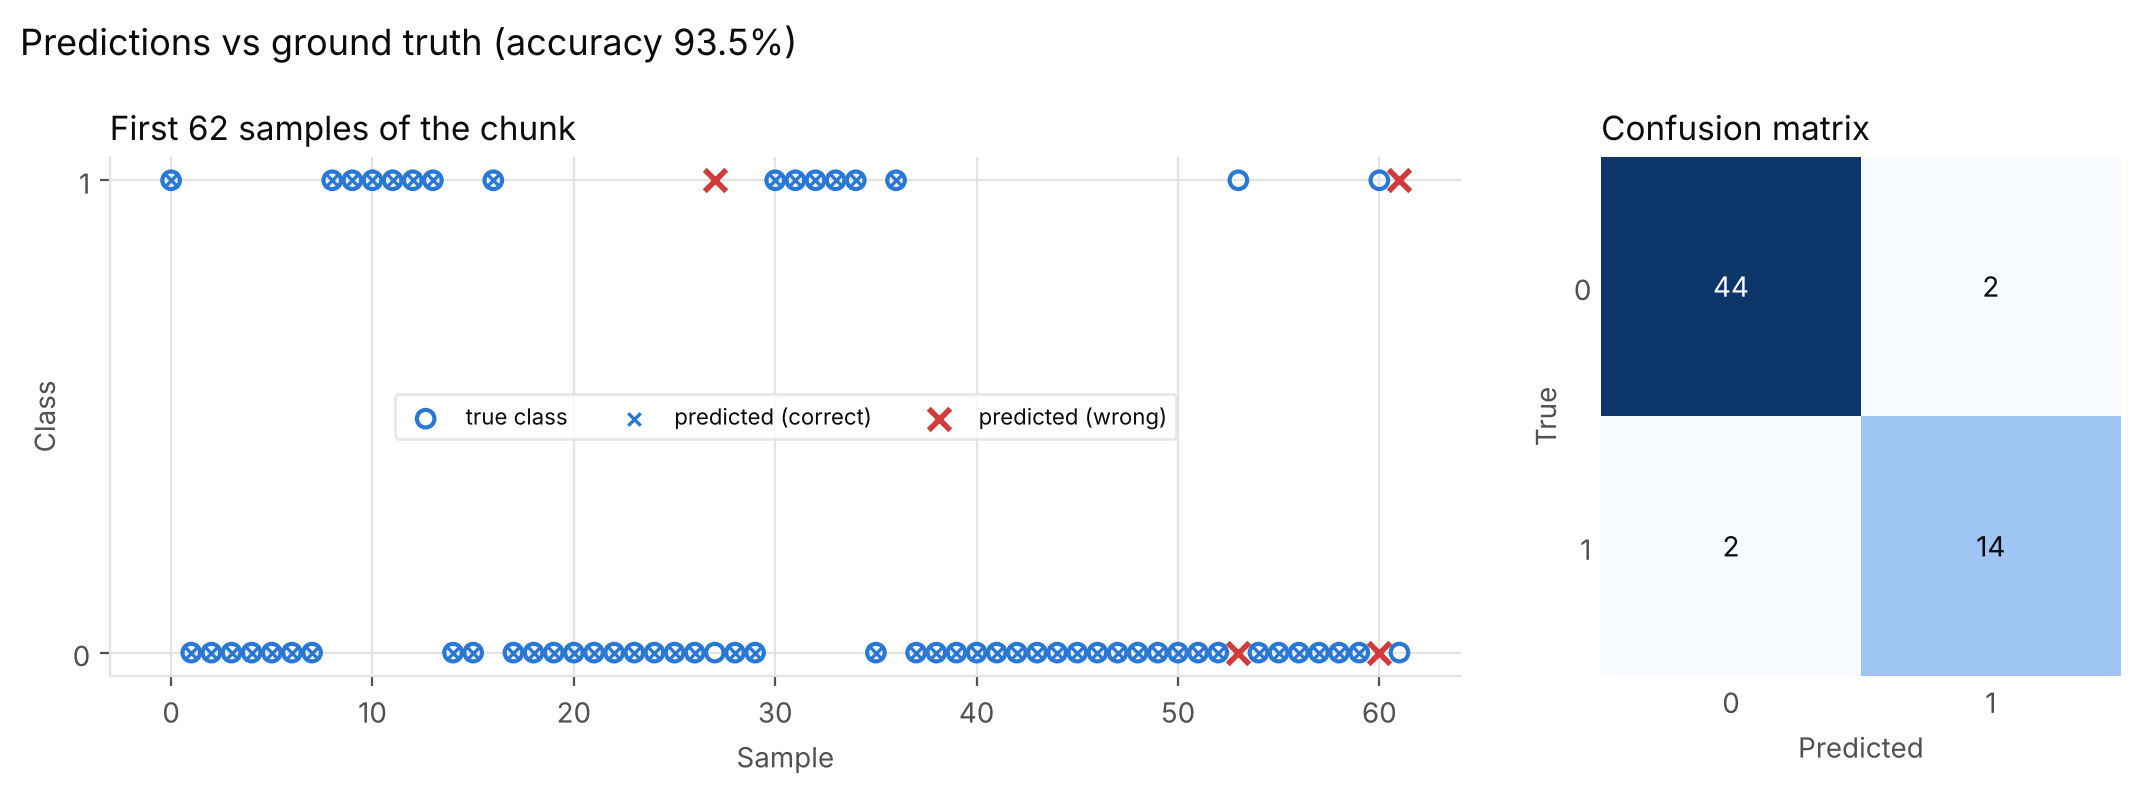

In [9]:
X_last, y_last, _ = chunks[-1]
y_pred = pipe.predict(X_last)
plot_predictions_vs_ground_truth(y_last, y_pred, max_points=120,
                                 save_path=FIGURES / "predictions_latest_chunk.png")

# Now let the model learn from it too (test-then-train).
trainer.process_chunk(X_last, y_last);

## 7. Look inside the current tree

A decision tree can be read as a set of if/else rules. The thresholds are in *scaled* units, because the tree sits after the `StandardScaler`.

In [10]:
tree = pipe["model"]
print("depth:", tree.get_depth(), "| leaves:", tree.get_n_leaves(),
      "| retrains so far:", tree.n_retrains_)
print(tree.export_text(feature_names)[:1500])

depth: 5 | leaves: 25 | retrains so far: 45
if nswprice <= 0.286:
|   if nswprice <= -0.103:
|   |   if transfer <= 1.16:
|   |   |   if nswdemand <= 0.654:
|   |   |   |   if period <= 1.588:
|   |   |   |   |   predict 0 (samples=459)
|   |   |   |   else:  # period > 1.588
|   |   |   |   |   predict 1 (samples=11)
|   |   |   else:  # nswdemand > 0.654
|   |   |   |   predict 1 (samples=7)
|   |   else:  # transfer > 1.16
|   |   |   if period <= -0.685:
|   |   |   |   if nswprice <= -0.375:
|   |   |   |   |   predict 0 (samples=46)
|   |   |   |   else:  # nswprice > -0.375
|   |   |   |   |   predict 0 (samples=13)
|   |   |   else:  # period > -0.685
|   |   |   |   if vicdemand <= -1.008:
|   |   |   |   |   predict 1 (samples=66)
|   |   |   |   else:  # vicdemand > -1.008
|   |   |   |   |   predict 0 (samples=22)
|   else:  # nswprice > -0.103
|   |   if transfer <= -0.669:
|   |   |   if nswdemand <= 0.537:
|   |   |   |   if nswprice <= 0.273:
|   |   |   |   |   predict

## 8. Robustness check: missing values

The Electricity data has no missing values, so here we **deliberately blank out 2% of the cells** to show the pipeline still works: the `Imputer` fills them with running means that update chunk by chunk. (This is an artificial test, not part of the real data.)

In [11]:
rng = np.random.default_rng(0)
X_missing = X.copy()
X_missing[rng.random(X.shape) < 0.02] = np.nan
print("cells set to NaN:", int(np.isnan(X_missing).sum()))

robust = StreamTrainer(Pipeline([
    ("impute", Imputer()), ("scale", StandardScaler()),
    ("model", DecisionTreeClassifier(max_depth=5, buffer_size=1000))]))
robust.run(chunk_array(X_missing, y, chunk_size=CHUNK_SIZE))
print("final accuracy with 2% missing:",
      round(robust.summary()["final_cumulative_accuracy"], 4))
print("final accuracy without missing:",
      round(trainer.summary()["final_cumulative_accuracy"], 4))

cells set to NaN: 5357


final accuracy with 2% missing: 0.7284
final accuracy without missing: 0.7464


## 9. Sliding-window histogram

`StreamingHistogram` with `window=20` only counts the last 20 chunks, so it shows the *current* price distribution instead of the whole history.

values above the histogram range: 250


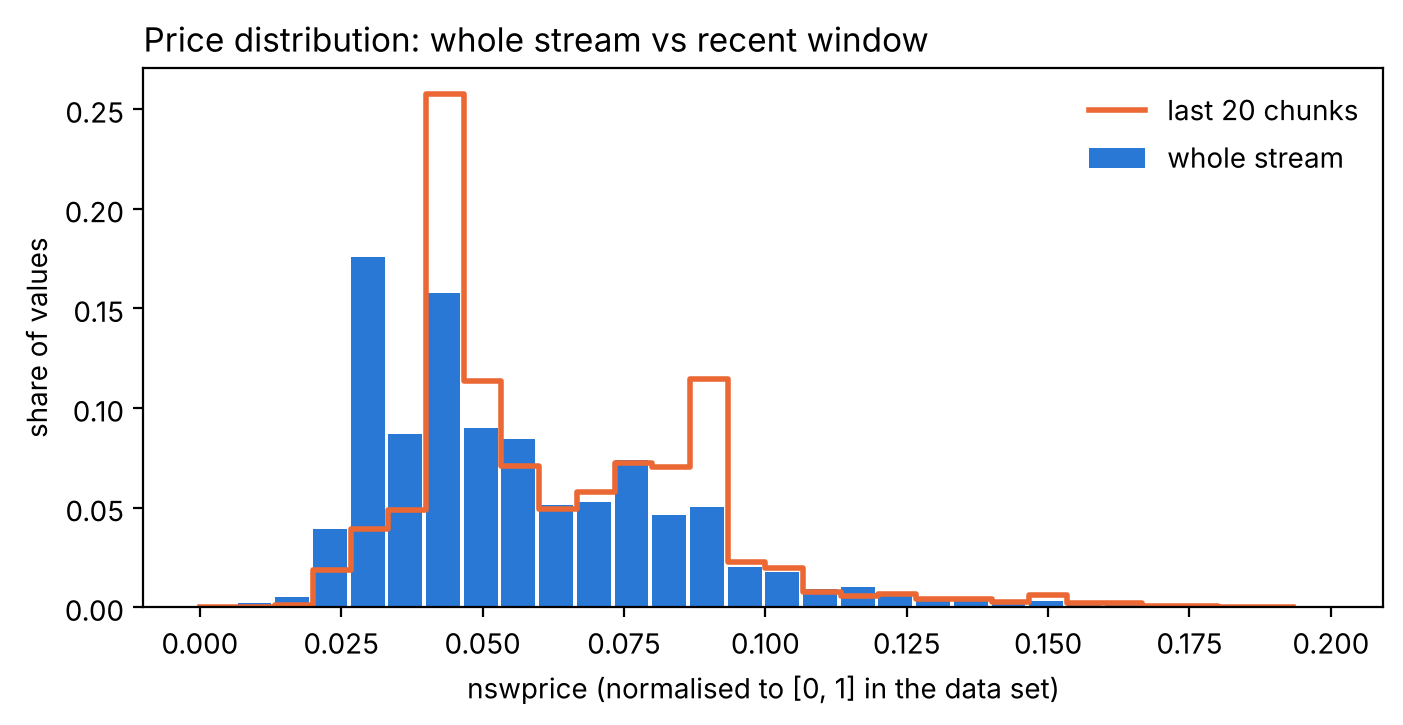

In [12]:
import matplotlib.pyplot as plt

price = feature_names.index("nswprice")
whole = StreamingHistogram(bins=30, value_range=(0, 0.2))
recent = StreamingHistogram(bins=30, value_range=(0, 0.2), window=20)
for X_chunk, _, _ in chunks:
    whole.update_stats(X_chunk[:, price])
    recent.update_stats(X_chunk[:, price])

fig, ax = plt.subplots(figsize=(8, 3.5))
edges = whole.edges_
width = edges[1] - edges[0]
ax.bar(edges[:-1], whole.counts_ / whole.counts_.sum(), width=width * 0.9,
       align="edge", color="#2a78d6", label="whole stream")
ax.step(edges[:-1], recent.counts_ / recent.counts_.sum(), where="post",
        color="#eb6834", linewidth=2, label="last 20 chunks")
ax.set_xlabel("nswprice (normalised to [0, 1] in the data set)"); ax.set_ylabel("share of values")
ax.set_title("Price distribution: whole stream vs recent window", loc="left")
ax.legend(frameon=False)
print("values above the histogram range:", whole.n_above_)

## Summary

* The CSV was loaded and streamed with our own `io.py`; every component learned incrementally through `partial_fit` / `update` / `update_stats`.
* The buffered tree retrains every `buffer_size` rows; test-then-train evaluation gives an honest accuracy of about 75% on this drifting stream.
* Smaller buffers adapt faster to drift but retrain more often; larger buffers cost more per retrain and react slowly (see also `benchmark/bench_buffer_size.py`).
* Figures for the report are saved in `demo/figures/`.